# Comparing TailBondy and TailCurve on the Same Bootstrap Draws

In [1]:
import numpy as np
import pandas as pd

import chainladder as cl

`BootstrapODPSample` gives a distribution of IBNR for each reserving
choice. Two histograms side by side, as in
{doc}`BootstrapODPSample Variability <plot_bootstrap_comparison>`, show how
wide each distribution is. They do not show how far apart two choices
are on the same data. That needs the difference between the two choices
on each simulated triangle.

Fitting both choices to the same resampled triangles gives that
difference directly {cite}`shapland2016`. Both choices see the same
simulated claims, so most of the sampling noise cancels out of the
difference. This example compares two tail estimators, `TailCurve` and
`TailBondy`, on `genins`.

Start with the deterministic baselines. `point_ibnr` develops the
original `genins` triangle, applies one tail estimator and returns total
IBNR from `Chainladder`. The bootstrap results below should center near
the difference between these two totals.

In [2]:
genins = cl.load_sample("genins")


def point_ibnr(tail):
    developed = tail.fit_transform(cl.Development().fit_transform(genins))
    return cl.Chainladder().fit(developed).ibnr_.sum()


point = pd.Series({
    "TailCurve": point_ibnr(cl.TailCurve()),
    "TailBondy": point_ibnr(cl.TailBondy()),
})
point["Difference"] = point["TailBondy"] - point["TailCurve"]
point.round(0)

TailCurve     20245461.0
TailBondy     19620956.0
Difference     -624504.0
dtype: float64

On the original triangle TailCurve gives total IBNR of 20,245,461 and
TailBondy gives 19,620,956, a difference of -624,504.

Next come the draws. `sims` holds 1,000 resampled triangles from seed
42, and both tail estimators are fitted to it. These are the shared
draws. `other` holds 1,000 triangles from a second seed, 7, and only
TailBondy is fitted to it. Subtracting TailCurve on `sims` from TailBondy
on `other` gives the difference on independent draws.

In [3]:
def total_ibnr(triangles, tail):
    developed = tail.fit_transform(cl.Development().fit_transform(triangles))
    return cl.Chainladder().fit(developed).ibnr_.sum("origin").values.flatten()


sims = cl.BootstrapODPSample(n_sims=1000, random_state=42).fit_transform(genins)
other = cl.BootstrapODPSample(n_sims=1000, random_state=7).fit_transform(genins)

curve = total_ibnr(sims, cl.TailCurve())
bondy = total_ibnr(sims, cl.TailBondy())
bondy_other = total_ibnr(other, cl.TailBondy())

differences = pd.DataFrame({
    "Same draws": bondy - curve,
    "Independent draws": bondy_other - curve,
})
differences.describe(percentiles=[0.05, 0.5, 0.95]).T.round(0)

,count,mean,std,min,5%,50%,95%,max
Same draws,1000.0,-696715.0,1540822.0,-5697463.0,-3309382.0,-686915.0,1790523.0,4237244.0
Independent draws,1000.0,-702384.0,4728455.0,-14099955.0,-8044041.0,-955422.0,7262379.0,16383097.0


## Independent draws give a wider difference

Both rows estimate the same mean difference, TailBondy minus TailCurve,
and both sit near the baseline of -624,504. Their spreads differ. The
next cell prints the standard deviation of each method's total IBNR and
of each difference.

In [4]:
pd.Series({
    "sd of TailCurve on sims": curve.std(ddof=1),
    "sd of TailBondy on sims": bondy.std(ddof=1),
    "sd of TailBondy on other": bondy_other.std(ddof=1),
    "sd of the difference, same draws": differences["Same draws"].std(),
    "sd of the difference, independent draws": differences["Independent draws"].std(),
}).round(0)

sd of TailCurve on sims                    3253497.0
sd of TailBondy on sims                    3176469.0
sd of TailBondy on other                   3468130.0
sd of the difference, same draws           1540822.0
sd of the difference, independent draws    4728455.0
dtype: float64

Each method alone has a standard deviation between 3,176,469 and
3,468,130. The difference on independent draws has a standard deviation
of 4,728,455, larger than either method alone. The difference on shared
draws has 1,540,822, about a third of that and smaller than either
method alone. The next section explains why.

## The variance of a difference

The variance of a difference explains the gap:

$$
\operatorname{Var}(B - C) = \operatorname{Var}(B) + \operatorname{Var}(C) - 2\operatorname{Cov}(B, C)
$$

With independent draws the covariance is zero. With shared draws the two
totals move together, and the covariance cancels most of the variance.
When the two methods have about the same standard deviation $\sigma$
and correlation $\rho$, the shared-draw variance is
$2\sigma^2(1 - \rho)$ against $2\sigma^2$, so the ratio of standard
deviations is close to $\sqrt{1 - \rho}$.

In [5]:
rho = np.corrcoef(curve, bondy)[0, 1]
sd_curve = curve.std(ddof=1)
sd_bondy = bondy.std(ddof=1)
sd_identity = np.sqrt(sd_bondy**2 + sd_curve**2 - 2 * rho * sd_bondy * sd_curve)
sd_same = differences["Same draws"].std()
sd_independent = differences["Independent draws"].std()
pd.Series({
    "Correlation of TailCurve and TailBondy": rho,
    "Correlation on independent draws": np.corrcoef(curve, bondy_other)[0, 1],
    "sd of the difference from the identity": sd_identity,
    "sd of the difference on shared draws": sd_same,
    "sqrt(1 - correlation)": np.sqrt(1 - rho),
    "Ratio of shared to independent sd": sd_same / sd_independent,
}).round(3)

Correlation of TailCurve and TailBondy          0.885
Correlation on independent draws                0.011
sd of the difference from the identity    1540821.818
sd of the difference on shared draws      1540821.818
sqrt(1 - correlation)                           0.338
Ratio of shared to independent sd               0.326
dtype: float64

The correlation is 0.885 on shared draws and 0.011 on independent
draws. On shared draws $\sqrt{1 - \rho}$ is 0.338 and the observed
ratio is 0.326. The identity reproduces the shared-draw standard
deviation exactly, because it uses the sample covariance of the same
draws.

The scatter plot shows the same correlation. Each point is one simulated
triangle, with TailBondy total IBNR across and TailCurve total IBNR up.
The dashed line marks equal totals, and the horizontal distance from a
point to that line is the difference for that triangle.

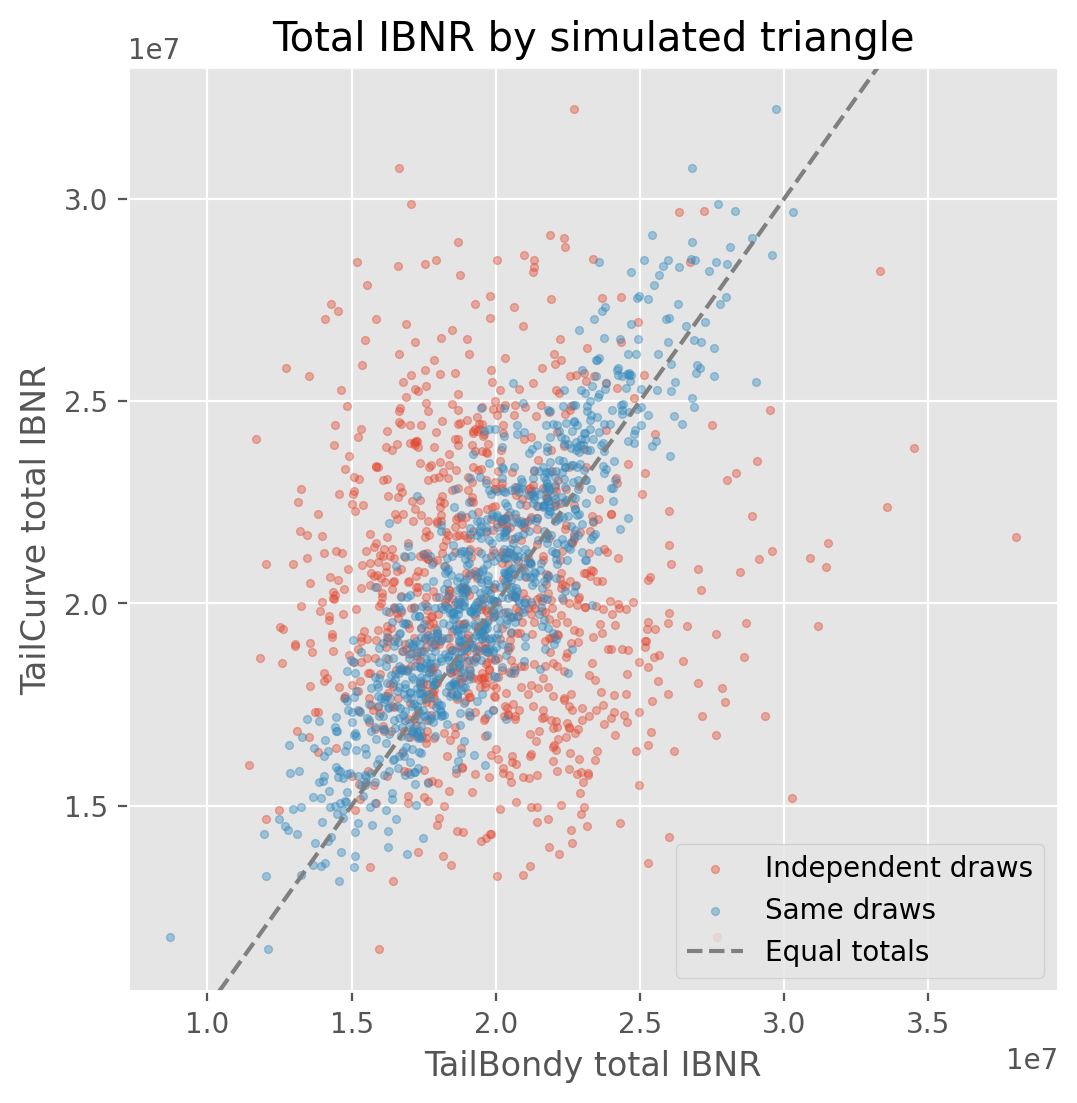

In [6]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(bondy_other, curve, s=8, alpha=0.4, label="Independent draws")
ax.scatter(bondy, curve, s=8, alpha=0.4, label="Same draws")
ax.set_xlabel("TailBondy total IBNR")
ax.set_ylabel("TailCurve total IBNR")
ax.set_title("Total IBNR by simulated triangle")
ax.axline((2e7, 2e7), slope=1, color="grey", linestyle="--", label="Equal totals")
ax.legend();

On shared draws the points lie in a narrow rising band close to the
dashed line. A triangle that gives TailBondy a high total gives
TailCurve a high total too. On independent draws the points form a
round cloud with no trend, so the distance to the line varies far more.
The histogram below shows the two sets of differences.

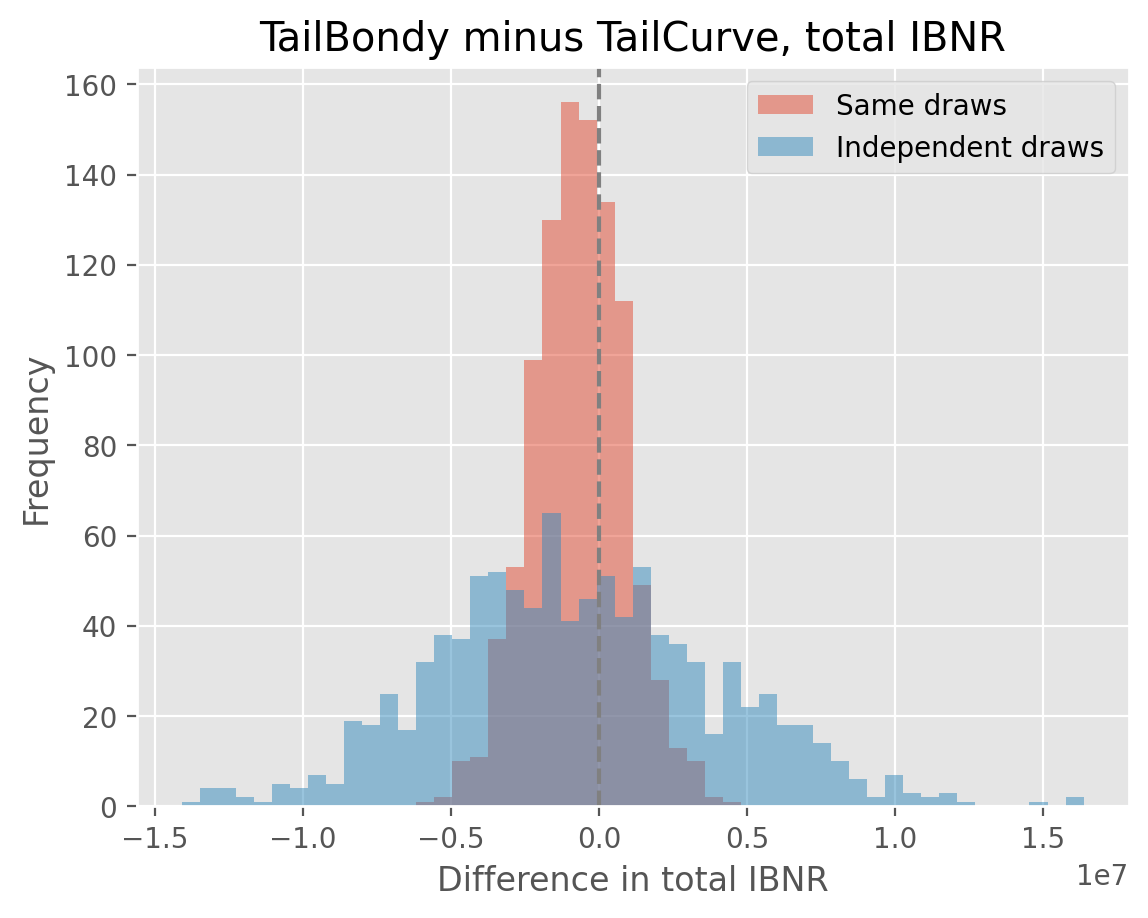

In [7]:
ax = differences.plot(
    kind="hist",
    bins=50,
    alpha=0.5,
    grid=True,
    title="TailBondy minus TailCurve, total IBNR",
    xlabel="Difference in total IBNR",
)
ax.axvline(0, color="grey", linestyle="--");

## More draws

More draws do not close this gap. Each standard deviation describes the
spread of one difference across simulated triangles, and it settles at
its own value as the number of draws grows. What more draws shrink is
the standard error of the mean difference, which falls like
$1 / \sqrt{n}$.

In [8]:
rows = []
for n in (200, 1000, 2000):
    sims_n = cl.BootstrapODPSample(n_sims=n, random_state=42).fit_transform(genins)
    other_n = cl.BootstrapODPSample(n_sims=n, random_state=7).fit_transform(genins)
    curve_n = total_ibnr(sims_n, cl.TailCurve())
    same = total_ibnr(sims_n, cl.TailBondy()) - curve_n
    independent = total_ibnr(other_n, cl.TailBondy()) - curve_n
    rows.append({
        "Draws": n,
        "sd, same draws": same.std(ddof=1),
        "sd, independent draws": independent.std(ddof=1),
        "Ratio": same.std(ddof=1) / independent.std(ddof=1),
        "Mean, same draws": same.mean(),
        "Standard error of the mean": same.std(ddof=1) / np.sqrt(n),
    })
by_draws = pd.DataFrame(rows).set_index("Draws")
by_draws["Mean over standard error"] = (
    by_draws["Mean, same draws"] / by_draws["Standard error of the mean"]
)
by_draws.round(0).assign(**{
    "Ratio": by_draws["Ratio"].round(3),
    "Mean over standard error": by_draws["Mean over standard error"].round(1),
})

,"sd, same draws","sd, independent draws",Ratio,"Mean, same draws",Standard error of the mean,Mean over standard error
Draws,,,,,,
200,1488592.0,4917204.0,0.303,-537354.0,105259.0,-5.1
1000,1540822.0,4728455.0,0.326,-696715.0,48725.0,-14.3
2000,1580905.0,4773806.0,0.331,-688972.0,35350.0,-19.5


The ratio stays between 0.303 and 0.331 from 200 to 2,000 draws.
The standard error of the shared-draw mean falls from 105,259 to
35,350, so the mean difference of -688,972 at 2,000 draws sits
about 19.5 standard errors below zero. With independent draws
the standard error would be about three times as large at every number
of draws, since it scales with the wider standard deviation.

The comparison depends on one seed giving the same draws to both
methods. Fit each method to the output of a single
`BootstrapODPSample.fit_transform` call, as above, rather than
resampling once per method.